# Fermion to Qubit Via JW

## For a particular Theta

SparsePauliOp(['IXZX', 'IYZY', 'XZXI', 'YZYI'],
              coeffs=[0.39269908+0.j, 0.39269908+0.j, 0.39269908+0.j, 0.39269908+0.j])
SparsePauliOp(['IIII', 'IIIZ', 'IIZI'],
              coeffs=[ 0.78539816+0.j, -0.39269908+0.j, -0.39269908+0.j])
{'1001': 2468, '1100': 2529, '0110': 2518, '0011': 2485}


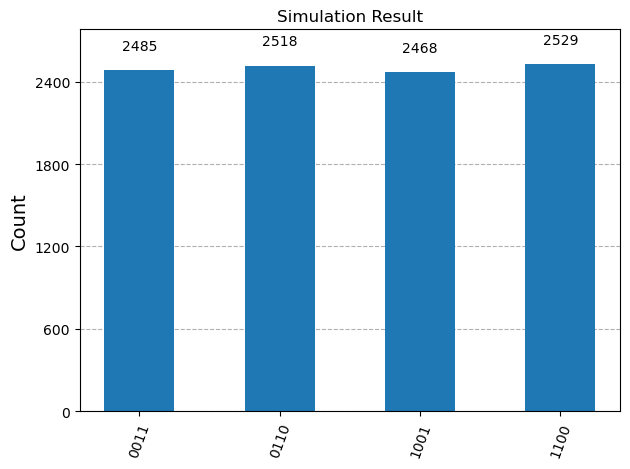

In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Operator, Pauli
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram
from qiskit.synthesis import LieTrotter
from qiskit_aer import AerSimulator
from IPython.display import display, Math
import matplotlib.pyplot as plt
%matplotlib inline

X=Operator(Pauli("X")).data
Y=Operator(Pauli("Y")).data
Z=Operator(Pauli("Z")).data
I=np.eye(2,dtype=complex)

sigma_plus=0.5*(X - 1j*Y)
sigma_minus=0.5*(X + 1j*Y)

b11cr=np.kron(np.kron(np.kron(sigma_plus,I),I),I)
b11an=np.kron(np.kron(np.kron(sigma_minus,I),I),I) 

b12cr=np.kron(np.kron(np.kron(Z,sigma_plus),I),I)
b12an=np.kron(np.kron(np.kron(Z,sigma_minus),I),I)

b21cr=np.kron(np.kron(np.kron(Z,Z),sigma_plus),I)
b21an=np.kron(np.kron(np.kron(Z,Z),sigma_minus),I)

b22cr=np.kron(np.kron(np.kron(Z,Z),Z),sigma_plus)
b22an=np.kron(np.kron(np.kron(Z,Z),Z),sigma_minus)

H_BS=(np.pi/4) * (b11cr@b21an + b21cr@b11an + b12cr@b22an + b22cr@b12an)

H_BS_P= SparsePauliOp.from_operator(Operator(H_BS))
H_BS_P=H_BS_P.simplify()
print(H_BS_P)

H_PS=(np.pi/4) * (b21cr@b21an + b22cr@b22an)

H_PS_P= SparsePauliOp.from_operator(Operator(H_PS))
H_PS_P=H_PS_P.simplify()
print(H_PS_P)

def BScircuit():
    qc=QuantumCircuit(4,4)
    qc.x(1)
    qc.x(2)
    qc.h(0)
    qc.z(0)
    qc.cx(0,1)
    qc.cx(0,2)
    qc.cx(0,3)
    evolution1= PauliEvolutionGate(H_BS_P,time=1,label="U_BS")
    qc.append(evolution1,[0,1,2,3])
    evolution2= PauliEvolutionGate(H_PS_P,time=1,label="U_PS")
    qc.append(evolution2,[0,1,2,3])
    evolution3= PauliEvolutionGate(H_BS_P,time=1,label="U_BS")
    qc.append(evolution3,[0,1,2,3])
    qc.measure(range(4),range(4))
    return qc

backend=AerSimulator()
compiled_circuit=transpile(BScircuit(), backend)
job = backend.run(compiled_circuit, shots=10000)
    
result = job.result()
counts = result.get_counts()
print(counts)     
plot_histogram(counts, title="Simulation Result")
plt.show()

In [39]:
H_PS_P==H_BS_P

False

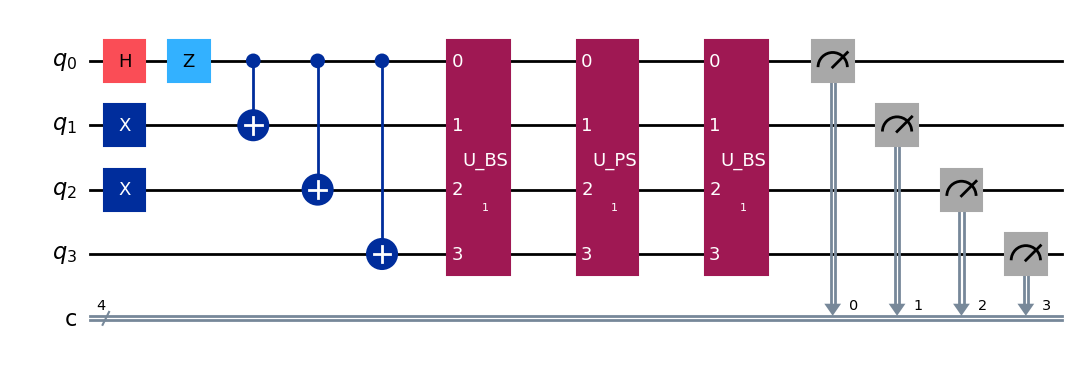

In [51]:
BScircuit().draw("mpl")
plt.show()

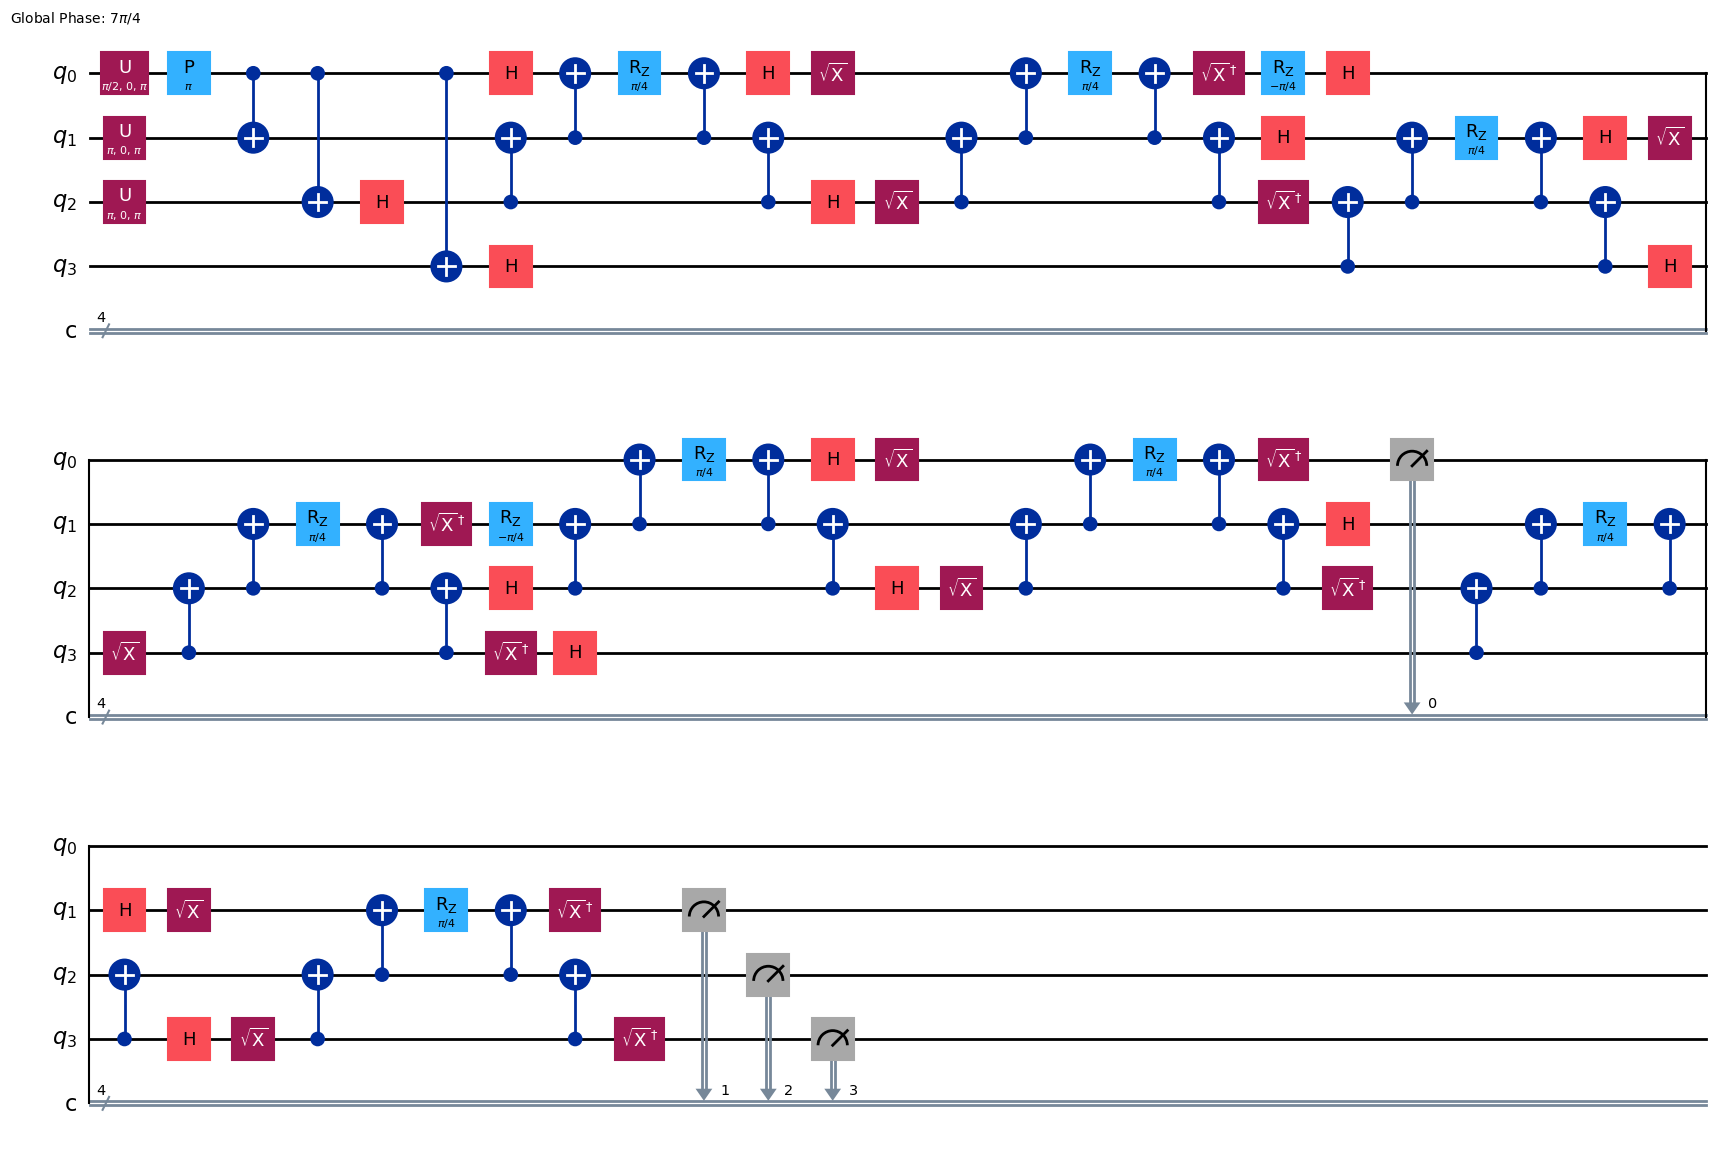

In [52]:
decomposed_circuit=BScircuit().decompose()
decomposed_circuit.draw("mpl")
plt.show()

In [55]:
print(decomposed_circuit.depth())

58


In [54]:
print(decomposed_circuit.count_ops())


OrderedDict({'cx': 35, 'h': 16, 'rz': 10, 'sx': 8, 'sxdg': 8, 'measure': 4, 'u': 3, 'p': 1})


## Theta Sweep

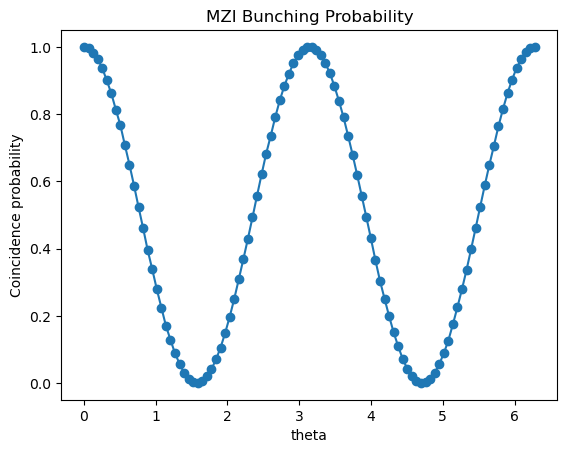

In [76]:

def BScircuit(phi):
    H_PS= phi* (b21cr@b21an + b22cr@b22an)

    H_PS_P= SparsePauliOp.from_operator(Operator(H_PS))
    H_PS_P=H_PS_P.simplify()
    qc=QuantumCircuit(4,4)
    qc.x(1)
    qc.x(2)
    qc.h(0)
    qc.z(0)
    qc.cx(0,1)
    qc.cx(0,2)
    qc.cx(0,3)
    evolution1= PauliEvolutionGate(H_BS_P,time=1,label="U_BS")
    qc.append(evolution1,[0,1,2,3])
    evolution2= PauliEvolutionGate(H_PS_P,time=1,label="U_PS")
    qc.append(evolution2,[0,1,2,3])
    evolution3= PauliEvolutionGate(H_BS_P,time=1,label="U_BS")
    qc.append(evolution3,[0,1,2,3])
    qc.measure(range(4),range(4))
    return qc

def coincidence_probability(counts, shots):
    total = 0
    for bitstring, c in counts.items():
        bits = bitstring[::-1]   
        m1 = sum(int(b) for b in bits[0:2])
        m2 = sum(int(b) for b in bits[2:4])
        if m1 == 1 and m2 == 1:
            total += c
    return total / shots

backend=AerSimulator()
shots=100000
thetas=np.linspace(0,2*np.pi,100)
coincidences=[]

for phi in thetas:
    qc=BScircuit(phi)
    compiled=transpile(qc,backend)
    job=backend.run(compiled, shots=shots)
    result=job.result()
    counts=result.get_counts()
    coincidences.append(coincidence_probability(counts,shots))

plt.plot(thetas, coincidences, 'o-')
plt.xlabel("theta")
plt.ylabel("Coincidence probability")
plt.title("MZI Bunching Probability")
plt.show()

